# TP4 - Redes convolucionales para clasificar lesiones de piel (ISIC)

**Dataset:** imágenes dermatoscópicas ISIC de 9 clases (~880 imágenes en la carpeta `data/Split_smol`, con una subcarpeta por clase dentro de `train/` y `val/`).

El **código ya está resuelto y probado**. Lo que se evalúa es **su análisis**. El cómputo lleva unos 15-20 minutos (medido en una CPU de 20 núcleos), y les queda la mayor parte de las 2 horas para interpretar resultados.

**Qué se trabaja en este TP:** análisis exploratorio, limpieza de duplicados y split, convoluciones, pooling y campo receptivo, comparación MLP vs. CNN, decisiones de arquitectura, resolución de entrada, data augmentation y evaluación final.
**Qué NO se repite** porque ya lo hicieron en los TP1 a TP3: búsqueda de hiperparámetros con Optuna, dropout/L2/BatchNorm como variables de estudio (la BatchNorm queda fija dentro del bloque convolucional), inicialización y logging con TensorBoard/MLflow.

**Cómo trabajar:** ejecuten de arriba hacia abajo, lean los outputs y completen las celdas **✏️** (observaciones de EDA, explicación del código convolucional y cuatro análisis). Las comparaciones usan **3 semillas** y reportan media ± desvío: una diferencia solo cuenta si supera ese ruido.

**Reglas metodológicas (las mismas de los TPs anteriores):**
- Las entradas van **normalizadas** (media y desvío por canal calculados **solo en train**).
- El **test se usa una sola vez**, en la sección 8. Todo lo demás se decide con validación.
- La augmentation se aplica **solo a train y después del split**.
- Las conclusiones tienen que **coincidir con los outputs** de su corrida.

## 0. Configuración
Si no tienen GPU, los valores por defecto funcionan en CPU. Si cambian alguna constante, **anótenlo en su análisis**.

In [1]:
# Descarga el repo con el dataset y se para en su carpeta (necesario en Colab)
!git clone https://github.com/cselmo/CNN-en-Skin-Dataset
%cd CNN-en-Skin-Dataset

Cloning into 'CNN-en-Skin-Dataset'...
remote: Enumerating objects: 872, done.
remote: Total 872 (delta 0), reused 0 (delta 0), pack-reused 872 (from 1)
Receiving objects: 100% (872/872), 167.56 MiB | 6.79 MiB/s, done.
Resolving deltas: 100% (2/2), done.
/content/CNN-en-Skin-Dataset


### Constantes y cambios respecto del notebook original

No cambié ninguna constante de la sección 0. El único agregado es la celda de arriba, que descarga el dataset con `git clone`, porque el notebook se ejecutó en Google Colab: en Windows no se pudo descomprimir el dataset, ya que algunos nombres de archivo superan el largo máximo de ruta. Por eso los tiempos están medidos en GPU y no en CPU. Además, en GPU los resultados no son exactamente repetibles: la misma configuración base dio val_acc 0,6154, 0,6075 y 0,6114 en las secciones 5, 6 y 7, y tomo esa variación de alrededor de 0,01 como parte del ruido.

In [2]:
import os, time, random, copy, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import warnings; warnings.filterwarnings("ignore")

DATA_DIR    = "data/Split_smol"    # carpeta con train/ y val/ (una subcarpeta por clase)
SIZES       = [32, 64, 96]         # resoluciones de entrada que se van a comparar
SEEDS       = [0, 1, 2]            # semillas para medir ruido
MAX_EPOCHS  = 60                   # épocas máximas (con early stopping)
PATIENCE    = 10                   # épocas sin mejorar val_loss antes de cortar
BATCH       = 32
AUG_COPIES  = 2                    # copias aumentadas que se agregan a cada imagen de train
SEED_SPLIT  = 42                   # semilla del split (NO cambiarla entre corridas)
SEEDS_FINAL = [0, 1, 2, 3, 4]      # semillas de la evaluación final

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
print("Dispositivo:", device, "| torch", torch.__version__)

Dispositivo: cuda | torch 2.14.1+cu130


## 1. Análisis exploratorio (EDA)
Antes de modelar hay que mirar los datos: cuántas imágenes hay por clase, de qué tamaños son, cómo se ven y si hay algo raro (desbalance, resoluciones distintas por clase, **imágenes repetidas**). Acá todavía no se divide nada: se trabaja con todas las imágenes tal como vienen.

In [3]:
class_names = sorted(os.listdir(f"{DATA_DIR}/train")); NUM_CLASSES = len(class_names)
meta = []
for sp in ["train", "val"]:
    for ci, c in enumerate(class_names):
        for f in sorted(os.listdir(f"{DATA_DIR}/{sp}/{c}")):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                p = f"{DATA_DIR}/{sp}/{c}/{f}"
                with Image.open(p) as im: w, h = im.size
                meta.append(dict(path=p, carpeta=sp, clase=c, y=ci, w=w, h=h, md5=hashlib.md5(open(p, "rb").read()).hexdigest()))
df = pd.DataFrame(meta); df["res"] = df["w"].astype(str) + "x" + df["h"].astype(str); df["aspecto"] = df["w"] / df["h"]
print(f"{len(df)} imágenes, {NUM_CLASSES} clases")

# Se cargan todas las imágenes una sola vez, ya redimensionadas a cuadrados, para todas las resoluciones
t0 = time.time(); RAW = {s: [] for s in SIZES}
for p in df["path"]:
    with Image.open(p) as im0:
        im = im0.convert("RGB")
        for s in SIZES: RAW[s].append(np.asarray(im.resize((s, s), Image.BILINEAR)))
X_U8 = {s: torch.from_numpy(np.stack(RAW[s])).permute(0, 3, 1, 2).contiguous() for s in SIZES}; del RAW
Y = torch.from_numpy(df["y"].values); labels = df["y"].values
print(f"Carga de imágenes: {time.time() - t0:.0f}s | tensor {tuple(X_U8[64].shape)} uint8")

878 imágenes, 9 clases
Carga de imágenes: 10s | tensor (878, 3, 64, 64) uint8


carpeta,train,val,All
clase,,,
Actinic keratosis,80,20,100
Atopic Dermatitis,81,21,102
Benign keratosis,80,20,100
Dermatofibroma,80,20,100
Melanocytic nevus,80,20,100
Melanoma,80,20,100
Squamous cell carcinoma,80,20,100
Tinea Ringworm Candidiasis,56,20,76
Vascular lesion,80,20,100


Resoluciones más frecuentes:


res,600x450,1024x768,294x222,1024x764,1022x767,767x576,919x802,1024x681
imágenes,400,135,102,74,21,12,6,5


Fracción de cada clase por resolución:


res,1022x767,1024x764,1024x768,294x222,600x450,otras
clase,,,,,,
Actinic keratosis,0.00,0.00,0.00,0.0,1.0,0.00
Atopic Dermatitis,0.00,0.00,0.00,1.0,0.0,0.00
Benign keratosis,0.00,0.74,0.00,0.0,0.0,0.26
Dermatofibroma,0.00,0.00,0.00,0.0,1.0,0.00
Melanocytic nevus,0.18,0.00,0.79,0.0,0.0,0.03
Melanoma,0.03,0.00,0.56,0.0,0.0,0.41
Squamous cell carcinoma,0.00,0.00,0.00,0.0,1.0,0.00
Tinea Ringworm Candidiasis,0.00,0.00,0.00,0.0,0.0,1.00
Vascular lesion,0.00,0.00,0.00,0.0,1.0,0.00


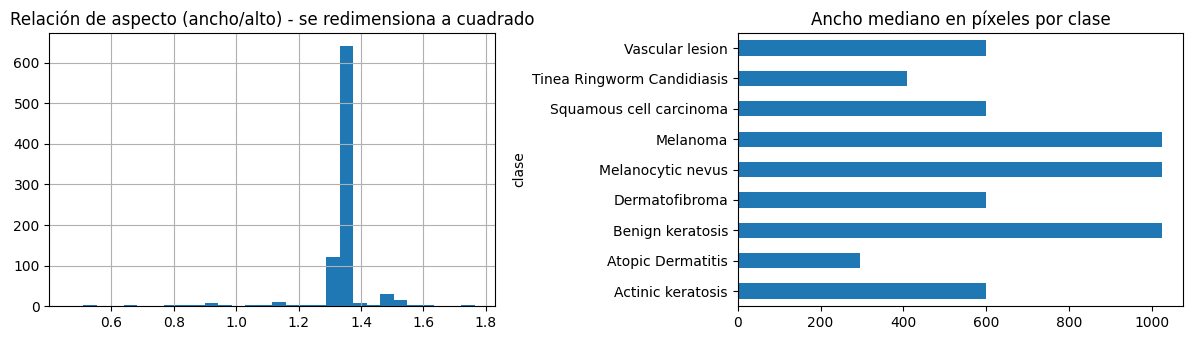

In [4]:
# 1.1 Clases y carpeta de origen
display(pd.crosstab(df["clase"], df["carpeta"], margins=True))
# 1.2 Resoluciones: ¿son todas iguales? ¿dependen de la clase?
print("Resoluciones más frecuentes:"); display(df["res"].value_counts().head(8).to_frame("imágenes").T)
top = df["res"].value_counts().head(5).index
ct = pd.crosstab(df["clase"], df["res"].where(df["res"].isin(top), "otras"), normalize="index").round(2)
print("Fracción de cada clase por resolución:"); display(ct)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df["aspecto"].hist(bins=30, ax=ax[0]); ax[0].set_title("Relación de aspecto (ancho/alto) - se redimensiona a cuadrado")
(df.groupby("clase")["w"].median()).plot.barh(ax=ax[1]); ax[1].set_title("Ancho mediano en píxeles por clase"); plt.tight_layout(); plt.show()

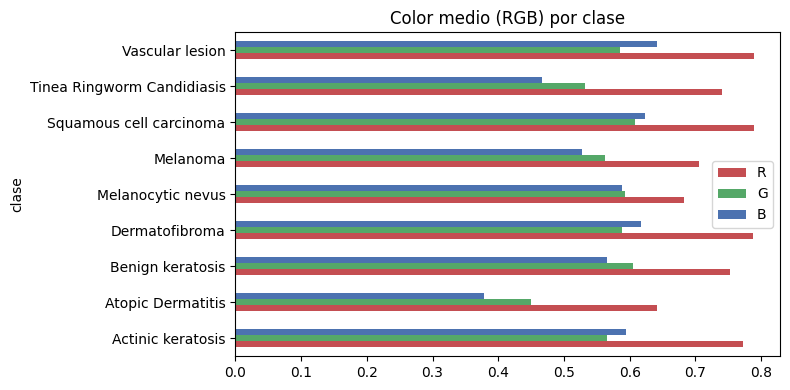

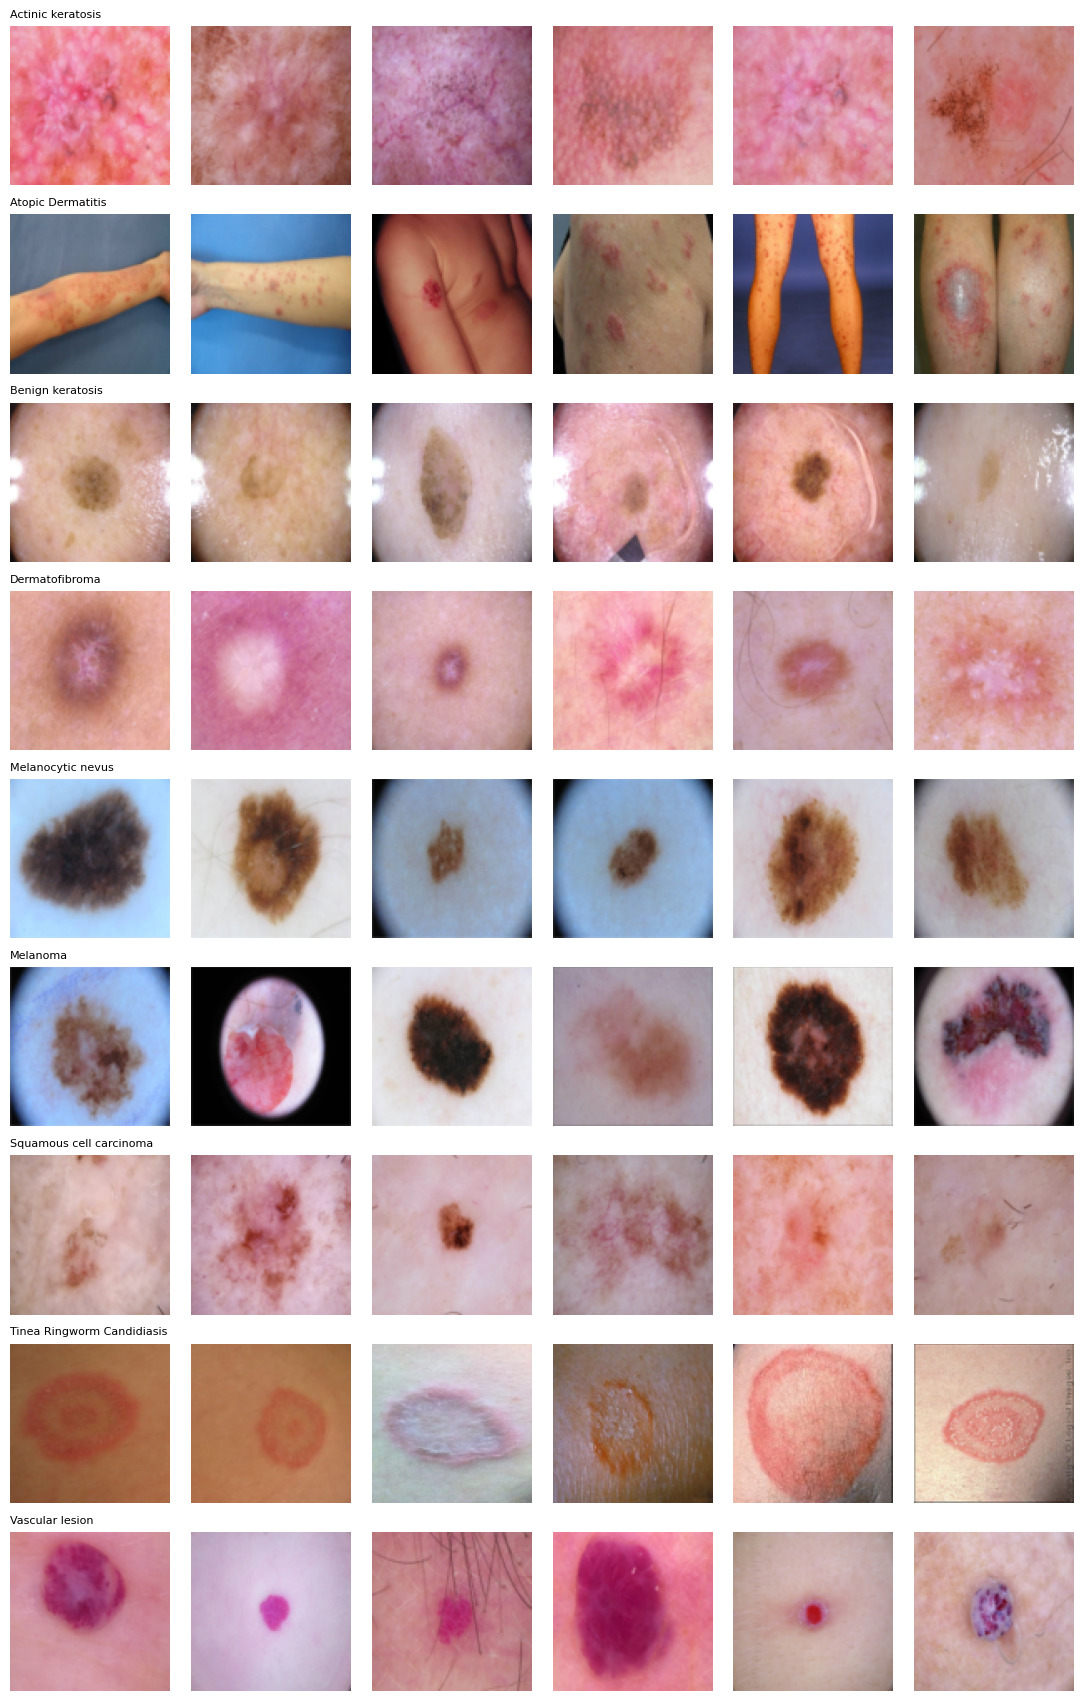

In [5]:
# 1.3 Color medio por clase y ejemplos
mean_rgb = pd.DataFrame(X_U8[32].float().mean((2, 3)).numpy() / 255, columns=["R", "G", "B"]); mean_rgb["clase"] = df["clase"].values
mean_rgb.groupby("clase").mean().plot.barh(color=["#c44e52", "#55a868", "#4c72b0"], figsize=(8, 4), title="Color medio (RGB) por clase"); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(11, 1.9 * NUM_CLASSES))
for ci in range(NUM_CLASSES):
    ids = np.where(labels == ci)[0][:6]
    for j, i in enumerate(ids): axes[ci, j].imshow(X_U8[96][i].permute(1, 2, 0)); axes[ci, j].axis("off")
    axes[ci, 0].set_title(class_names[ci], fontsize=8, loc="left")
plt.tight_layout(); plt.show()

### 1.4 Imágenes duplicadas
El dataset viene con una partición `train/`/`val/` propia. Si una misma imagen está en las dos carpetas, la validación **no mide generalización** (el modelo ya vio esas imágenes). Se buscan duplicados **exactos** (mismo hash MD5 del archivo) y se verifica con un hash perceptual (diferencias entre píxeles vecinos de una miniatura) que no queden **casi-duplicados** (recortes o recompresiones).

In [6]:
g = df.groupby("md5")
dup_groups = [idx for _, idx in g.groups.items() if len(idx) > 1]
cross = [idx for idx in dup_groups if df.loc[idx, "carpeta"].nunique() > 1]
print(f"Grupos de imágenes idénticas: {len(dup_groups)} (de los cuales {len(cross)} están repetidos entre train y val)")
print("Por clase:", df.loc[[idx[0] for idx in dup_groups], "clase"].value_counts().to_dict())
print("Conflictos de etiqueta (misma imagen con clases distintas):", sum(df.loc[idx, "y"].nunique() > 1 for idx in dup_groups))

# hash perceptual: miniatura gris 16x17, bit = pixel > vecino derecho (256 bits); distancia de Hamming
gray = X_U8[32].float().mean(1, keepdim=True)
th_ = F.interpolate(gray, size=(16, 17), mode="area")
H = (th_[..., 1:] > th_[..., :-1]).flatten(1).numpy()
near = []
for i in range(len(H)):
    d = (H[i] != H[i + 1:]).sum(1)
    near += [(i, i + 1 + j) for j in np.where(d <= 8)[0]]
near_not_exact = [(i, j) for i, j in near if df.loc[i, "md5"] != df.loc[j, "md5"]]
print(f"Pares con hash perceptual casi igual (<=8 bits de 256): {len(near)} | de ellos NO idénticos por MD5: {len(near_not_exact)}")

Grupos de imágenes idénticas: 34 (de los cuales 33 están repetidos entre train y val)
Por clase: {'Atopic Dermatitis': 22, 'Tinea Ringworm Candidiasis': 12}
Conflictos de etiqueta (misma imagen con clases distintas): 0
Pares con hash perceptual casi igual (<=8 bits de 256): 34 | de ellos NO idénticos por MD5: 0


### ✏️ TUS OBSERVACIONES DEL EDA
Respondan en pocas líneas, con los números de los outputs de arriba:
1. ¿Qué tan desbalanceado está el dataset? ¿Qué cambia respecto de la partición original `train`/`val`?
2. ¿Hay clases que se distinguen por resolución, relación de aspecto o color de fondo? ¿Qué riesgo tiene eso para un modelo que ve las imágenes redimensionadas?
3. ¿Qué duplicados encontraron, en qué clases y por qué importan para la validación? ¿Qué hubiera pasado con la `val_acc` si no los eliminaran?

---

**1.** El desbalance es moderado. Después de eliminar duplicados quedan 844 imágenes: 100 por clase, salvo Atopic Dermatitis (80) y Tinea (64), con una relación de 1,56 entre la clase más grande y la más chica. La partición original no servía para medir: no tenía test, y 33 de las 181 imágenes de `val/` (18%) también estaban en `train/`. El nuevo split estratificado (506/169/169) mantiene la proporción de cada clase en train, validación y test.

**2.** Sí, varias clases se reconocen solo por la resolución. Atopic Dermatitis es 100% de 294×222; Actinic keratosis, Dermatofibroma, Squamous cell carcinoma y Vascular lesion son 100% de 600×450; Benign keratosis es 74% de 1024×764, y nevus y melanoma son mayormente de 1024×768. Además, Atopic Dermatitis y Tinea son fotos clínicas con fondo, no dermatoscopías, y por eso Atopic Dermatitis es la clase más oscura en el color medio. El riesgo es que, aunque al redimensionar se pierda el tamaño original, quedan pistas del origen (fondo, reflejos, nitidez, deformación). El modelo podría aprender a reconocer cómo se sacó la foto en vez de la lesión, lo que inflaría la accuracy sin servir para imágenes de otra fuente.

**3.** Hay 34 grupos de imágenes idénticas por MD5: 22 en Atopic Dermatitis y 12 en Tinea, sin conflictos de etiqueta. En 33 de esos grupos hay una copia en train y otra en val. Como Atopic Dermatitis tenía 21 imágenes en `val/` y 22 grupos duplicados, todas sus imágenes de validación estaban también en train. El hash perceptual no encontró casi-duplicados aparte de esos. Sin eliminarlos, la validación habría medido memoria en vez de generalización, y la `val_acc` habría salido inflada, sobre todo en esas dos clases.

## 2. Eliminación de duplicados y split estratificado
- Se **elimina una copia de cada imagen duplicada** (se conserva una sola por grupo de MD5).
- Se juntan **todas** las imágenes que quedan (la partición original no sirve: tenía repetidas y no tenía test) y se hace un split **estratificado 60/20/20** con semilla fija. El test no se toca hasta la sección 8.
- Se calcula la **normalización** (media y desvío por canal) **solo con train**.

In [7]:
keep = df.groupby("md5").head(1).index.values            # una imagen por hash
print(f"Imágenes totales: {len(df)} -> sin duplicados: {len(keep)} (se eliminaron {len(df) - len(keep)})")
idx_tr, idx_tmp = train_test_split(keep, test_size=0.4, stratify=labels[keep], random_state=SEED_SPLIT)
idx_va, idx_te  = train_test_split(idx_tmp, test_size=0.5, stratify=labels[idx_tmp], random_state=SEED_SPLIT)
print(f"train {len(idx_tr)} | val {len(idx_va)} | test {len(idx_te)}")
print(pd.DataFrame({"train": pd.Series(df.loc[idx_tr, "clase"]).value_counts(), "val": pd.Series(df.loc[idx_va, "clase"]).value_counts(),
                    "test": pd.Series(df.loc[idx_te, "clase"]).value_counts()}).to_string())
assert not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_va, "md5"])) and not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_te, "md5"])) and not (set(df.loc[idx_va, "md5"]) & set(df.loc[idx_te, "md5"]))
STATS = {}
for s in SIZES:
    xt = X_U8[s][idx_tr].float() / 255
    STATS[s] = (xt.mean((0, 2, 3)).view(1, 3, 1, 1), xt.std((0, 2, 3)).view(1, 3, 1, 1))
print("mean/std por canal (64px, solo train):", STATS[64][0].flatten().numpy().round(3), STATS[64][1].flatten().numpy().round(3))

Imágenes totales: 878 -> sin duplicados: 844 (se eliminaron 34)
train 506 | val 169 | test 169
                            train  val  test
clase                                       
Actinic keratosis              60   20    20
Atopic Dermatitis              48   16    16
Benign keratosis               60   20    20
Dermatofibroma                 60   20    20
Melanocytic nevus              60   20    20
Melanoma                       60   20    20
Squamous cell carcinoma        60   20    20
Tinea Ringworm Candidiasis     38   13    13
Vascular lesion                60   20    20
mean/std por canal (64px, solo train): [0.743 0.572 0.565] [0.162 0.164 0.186]


## 3. Data augmentation a mano (solo sobre train, después del split)
No se usa ninguna librería de augmentation: las transformaciones están escritas con operaciones de tensores. Cada imagen de **train** se complementa con `AUG_COPIES` copias transformadas **ya generadas** (se calculan una vez, después del split, así que ninguna copia de una imagen de val/test puede filtrarse a train). Val y test **nunca** se aumentan.

Transformaciones disponibles: flips horizontal/vertical, rotaciones de 90° y brillo/contraste aleatorios. Las lesiones dermatoscópicas no tienen orientación privilegiada, pero el **color** es información diagnóstica.

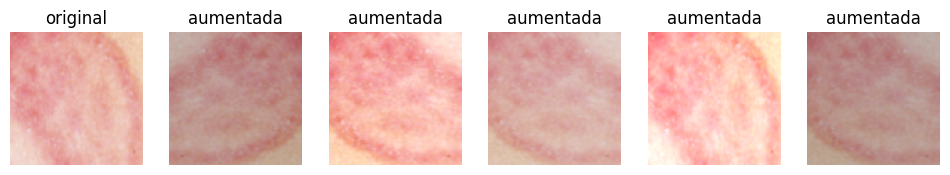

In [8]:
AUGS = {"ninguna": {}, "flips": dict(hflip=True, vflip=True),
        "flips+rot90": dict(hflip=True, vflip=True, rot90=True),
        "flips+rot90+color": dict(hflip=True, vflip=True, rot90=True, color=0.2)}

def augment(x, a):
    # x: tensor float [B,3,H,W] en [0,1]. Cada imagen recibe sus propias transformaciones al azar.
    B = x.shape[0]; x = x.clone()
    if a.get("hflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(3)
    if a.get("vflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(2)
    if a.get("rot90"):
        k = torch.randint(0, 4, (B,))
        for kv in (1, 2, 3):
            m = k == kv
            if m.any(): x[m] = torch.rot90(x[m], kv, (2, 3))
    if a.get("color"):
        c = a["color"]
        bri = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c; con = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c
        mu = x.mean((1, 2, 3), keepdim=True); x = ((x - mu) * con + mu) * bri
    return x.clamp(0, 1)

TRAIN_SETS = {}
def train_set(size, aug_name):
    # originales de train + AUG_COPIES copias aumentadas de cada una (generadas una vez, con semilla fija)
    key = (size, aug_name)
    if key not in TRAIN_SETS:
        x0, y0 = X_U8[size][idx_tr], Y[idx_tr]
        if aug_name == "ninguna": TRAIN_SETS[key] = (x0, y0)
        else:
            set_seed(1234); xs, ys = [x0], [y0]
            for _ in range(AUG_COPIES): xs.append((augment(x0.float() / 255, AUGS[aug_name]) * 255).round().to(torch.uint8)); ys.append(y0)
            TRAIN_SETS[key] = (torch.cat(xs), torch.cat(ys))
    return TRAIN_SETS[key]

# Vista de una imagen y sus versiones aumentadas
i0 = idx_tr[0]; base = X_U8[96][i0:i0 + 1].float() / 255; set_seed(3)
fig, ax = plt.subplots(1, 6, figsize=(12, 2.3)); ax[0].imshow(base[0].permute(1, 2, 0)); ax[0].set_title("original")
for k in range(1, 6): ax[k].imshow(augment(base, AUGS["flips+rot90+color"])[0].permute(1, 2, 0)); ax[k].set_title("aumentada")
for a in ax: a.axis("off")
plt.show()

## 4. Modelos y entrenamiento
- **`MLP`**: la referencia (Flatten + 2 capas ocultas).
- **`CNN`**: `n_blocks` bloques `Conv2d → BatchNorm → ReLU → MaxPool(2)` con `filters·2^b` canales, y una cabeza `Flatten → Linear(128) → ReLU → Dropout → Linear(clases)`.
- **`rf_full(...)`** calcula el **campo receptivo** teórico de la última capa convolucional.
- **Entrenamiento**: Adam, early stopping sobre `val_loss` restaurando el mejor estado, tiempo por época medido.

In [9]:
class MLP(nn.Module):
    def __init__(self, size, num_classes=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(3 * size * size, 512), nn.ReLU(),
                                 nn.Linear(512, 128), nn.ReLU(), nn.Linear(128, num_classes))
    def forward(self, x): return self.net(x)

class CNN(nn.Module):
    def __init__(self, size, n_blocks=3, filters=16, kernel=3, use_bn=True, dropout=0.2, num_classes=NUM_CLASSES):
        super().__init__()
        layers, cin = [], 3
        for b in range(n_blocks):
            cout = filters * 2 ** b
            layers += [nn.Conv2d(cin, cout, kernel, padding=kernel // 2, bias=not use_bn)]
            if use_bn: layers += [nn.BatchNorm2d(cout)]
            layers += [nn.ReLU(), nn.MaxPool2d(2)]
            cin = cout
        self.features = nn.Sequential(*layers)
        fs = size // 2 ** n_blocks                       # lado del mapa de activación después de los n_blocks pooling
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(cin * fs * fs, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, num_classes))
    def forward(self, x): return self.head(self.features(x))

def rf_full(n_blocks, kernel):
    # campo receptivo de la última conv: cada conv suma (k-1)*salto; cada maxpool(2) suma 1*salto y duplica el salto
    r, j = 1, 1
    for b in range(n_blocks):
        r += (kernel - 1) * j
        if b < n_blocks - 1: r += 1 * j; j *= 2
    return r
def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def norm_batch(x_u8, size):
    mu, sd = STATS[size]; return ((x_u8.float() / 255 - mu) / sd).to(device)

def get_eval_batch(size, ids, shift=0):
    x = X_U8[size][ids].float() / 255
    if shift:   # traslación circular aleatoria (solo para medir robustez a traslaciones)
        x = torch.stack([torch.roll(xi, shifts=(int(np.random.randint(-shift, shift + 1)), int(np.random.randint(-shift, shift + 1))), dims=(1, 2)) for xi in x])
    mu, sd = STATS[size]; return ((x - mu) / sd).to(device), Y[ids].to(device)

@torch.no_grad()
def evaluate(model, ids, size, shift=0):
    model.eval(); L, P = 0.0, []
    for i in range(0, len(ids), 256):
        xb, yb = get_eval_batch(size, ids[i:i + 256], shift)
        out = model(xb); L += F.cross_entropy(out, yb, reduction="sum").item(); P.append(out.argmax(1).cpu())
    P = torch.cat(P).numpy()
    return L / len(ids), accuracy_score(labels[ids], P), P

def make_model(cfg):
    if cfg["model"] == "mlp": return MLP(cfg["size"])
    return CNN(cfg["size"], cfg["n_blocks"], cfg["filters"], cfg["kernel"], cfg.get("use_bn", True), cfg["dropout"])

def fit(cfg, seed):
    set_seed(seed); model = make_model(cfg).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"]); size = cfg["size"]
    Xtr, Ytr = train_set(size, cfg["aug"])
    h = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[], epoch_time=[])
    best, best_ep, best_state, bad = 1e9, 0, None, 0
    for ep in range(MAX_EPOCHS):
        t0 = time.time(); model.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), BATCH):
            ids = perm[i:i + BATCH]
            if len(ids) < 2: continue
            opt.zero_grad(); F.cross_entropy(model(norm_batch(Xtr[ids], size)), Ytr[ids].to(device)).backward(); opt.step()
        if device.type == "cuda": torch.cuda.synchronize()
        h["epoch_time"].append(time.time() - t0)
        trl, tra, _ = evaluate(model, idx_tr, size)       # train ORIGINAL en modo eval (sin dropout ni copias aumentadas)
        vl, va, _ = evaluate(model, idx_va, size)
        h["train_loss"].append(trl); h["train_acc"].append(tra); h["val_loss"].append(vl); h["val_acc"].append(va)
        if vl < best - 1e-4: best, best_ep, best_state, bad = vl, ep, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    h.update(best_epoch=best_ep + 1, n_epochs=len(h["val_loss"]), n_params=n_params(model))
    return model, h

def run(cfg, seeds=SEEDS):
    # entrena la config con varias semillas y resume (media ± desvío)
    ms, hs = [], []
    for s in seeds:
        m, h = fit(cfg, s); ms.append(m); hs.append(h)
    be = [h["best_epoch"] - 1 for h in hs]
    va = [h["val_acc"][e] for h, e in zip(hs, be)]
    r = dict(val_acc=np.mean(va), val_acc_std=np.std(va), train_acc=np.mean([h["train_acc"][e] for h, e in zip(hs, be)]),
             val_loss=np.mean([min(h["val_loss"]) for h in hs]), best_epoch=np.mean([h["best_epoch"] for h in hs]),
             t_epoca_s=np.mean([np.mean(h["epoch_time"]) for h in hs]), t_total_s=np.mean([sum(h["epoch_time"]) for h in hs]), params=hs[0]["n_params"])
    r["brecha"] = r["train_acc"] - r["val_acc"]
    return r, ms, hs

BASE = dict(model="cnn", size=64, n_blocks=3, filters=16, kernel=3, dropout=0.2, lr=3e-3, aug="ninguna")
print("Parámetros CNN base (64px):", n_params(CNN(64)), "| MLP (64px):", n_params(MLP(64)), "| campo receptivo CNN base:", rf_full(3, 3), "px")

Parámetros CNN base (64px): 549273 | MLP (64px): 6358793 | campo receptivo CNN base: 18 px


### 4.1 Cómo se transforma una imagen dentro de la CNN
La tabla muestra, capa por capa, la **forma de la salida** `(canales, alto, ancho)` y la **cantidad de parámetros** de la CNN base con una imagen de 64×64.

In [10]:
def trace(model, size):
    model.eval(); x = torch.zeros(1, 3, size, size); rows = []
    for i, l in enumerate(list(model.features) + list(model.head)):
        x = l(x); rows.append(dict(capa=i, tipo=l.__class__.__name__, detalle=str(l)[:46], salida=tuple(x.shape[1:]), params=sum(p.numel() for p in l.parameters())))
    return pd.DataFrame(rows)
tr = trace(CNN(64), 64); display(tr); print("Total de parámetros:", tr["params"].sum())

,capa,tipo,detalle,salida,params
0,0,Conv2d,"Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1","(16, 64, 64)",432
1,1,BatchNorm2d,"BatchNorm2d(16, eps=1e-05, momentum=0.1, affin","(16, 64, 64)",32
2,2,ReLU,ReLU(),"(16, 64, 64)",0
3,3,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(16, 32, 32)",0
4,4,Conv2d,"Conv2d(16, 32, kernel_size=(3, 3), stride=(1,","(32, 32, 32)",4608
5,5,BatchNorm2d,"BatchNorm2d(32, eps=1e-05, momentum=0.1, affin","(32, 32, 32)",64
6,6,ReLU,ReLU(),"(32, 32, 32)",0
7,7,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(32, 16, 16)",0
8,8,Conv2d,"Conv2d(32, 64, kernel_size=(3, 3), stride=(1,","(64, 16, 16)",18432
9,9,BatchNorm2d,"BatchNorm2d(64, eps=1e-05, momentum=0.1, affin","(64, 16, 16)",128


Total de parámetros: 549273


### ✏️ EXPLICÁ EL CÓDIGO CONVOLUCIONAL
Con la clase `CNN` y la tabla de arriba, expliquen con sus palabras (y verificando con los números de la tabla):
1. **`padding=kernel // 2`**: ¿qué pasa con el alto y el ancho al aplicar la convolución? ¿Qué pasaría con `padding=0`? ¿Cómo se ve en la tabla?
2. **`MaxPool2d(2)`**: ¿qué hace con la forma de salida y qué información conserva? ¿Qué relación tiene con `fs = size // 2 ** n_blocks`?
3. **Parámetros:** calculen a mano cuántos parámetros tiene la segunda `Conv2d` (16 → 32 canales, kernel 3) y la primera `Linear` de la cabeza. Verifiquen con la tabla. ¿Cuál de las dos domina el total y por qué?
4. **`bias=not use_bn`:** ¿por qué la convolución no necesita sesgo cuando le sigue una BatchNorm?
5. **`filters * 2 ** b`:** ¿por qué se duplican los canales mientras se reduce la resolución a la mitad?
6. **`rf_full`:** reproduzcan a mano el campo receptivo de 18 px para 3 bloques con kernel 3 y expliquen qué significa ese número respecto de una imagen de 64 px.

---

**1.** Con kernel 3, el padding es 1: se agrega un borde de un píxel y la convolución no cambia el alto ni el ancho. En la tabla se ve en las tres convoluciones: 64×64 → (16, 64, 64), 32×32 → (32, 32, 32) y 16×16 → (64, 16, 16). Con `padding=0`, cada convolución perdería 2 píxeles (64 − 3 + 1 = 62) y `fs = size // 2 ** n_blocks` dejaría de dar el tamaño correcto.

**2.** `MaxPool2d(2)` se queda con el valor máximo de cada ventana de 2×2: divide alto y ancho por 2 y no cambia los canales. Por ejemplo, (16, 64, 64) → (16, 32, 32) en la capa 3, y así hasta (64, 8, 8) en la capa 11. Conserva si el patrón apareció en esa zona y pierde la posición exacta, y no tiene parámetros. Tres pooling llevan el lado a 64 / 2³ = 8 = `fs`, y por eso el `Flatten` da 64 × 8 × 8 = 4.096.

**3.** La segunda `Conv2d` tiene 32 filtros de 16 × 3 × 3 pesos, sin bias: 32 × 144 = **4.608**, como en la capa 4. La primera `Linear` tiene 4.096 × 128 + 128 = **524.416**, como en la capa 13. La `Linear` es el 95,5% de los 549.273 parámetros, porque tiene un peso distinto para cada posición del mapa, mientras que la convolución comparte sus pesos en todas las posiciones y solo mira ventanas de 3×3.

**4.** La BatchNorm le resta a cada canal su media en el batch, así que un bias constante sumado antes quedaría cancelado. Su función la cumple el parámetro β de la BatchNorm. Por eso la primera convolución tiene 432 = 16 × 3 × 3 × 3 parámetros, sin bias.

**5.** Al bajar la resolución, cada posición resume una zona más grande y combina más patrones, así que se necesitan más canales para representarlos. Duplicar los canales mientras cada lado se divide por 2 además mantiene parejo el costo: la segunda y la tercera convolución hacen unos 4,7 millones de multiplicaciones cada una.

**6.** Partiendo de r = 1 y salto j = 1, cada convolución suma (k − 1)·j y cada pooling suma 1·j y duplica el salto. Así: conv 1 → 3, pool → 4 (j = 2), conv 2 → 8, pool → 10 (j = 4), conv 3 → **18**. Cada neurona de la última convolución ve un parche de 18×18, el 28% del lado de la imagen: ninguna ve la lesión completa, y la forma global solo la puede combinar la `Linear`.

### 4.2 Chequeo rápido: el modelo aprende
Se entrena la CNN base con una semilla y se grafican curvas. Sirve para verificar que el pipeline funciona antes de correr los experimentos.

mejor época 15 | val_acc 0.669 | train_acc 0.866 | 0.15 s/época | total 11s


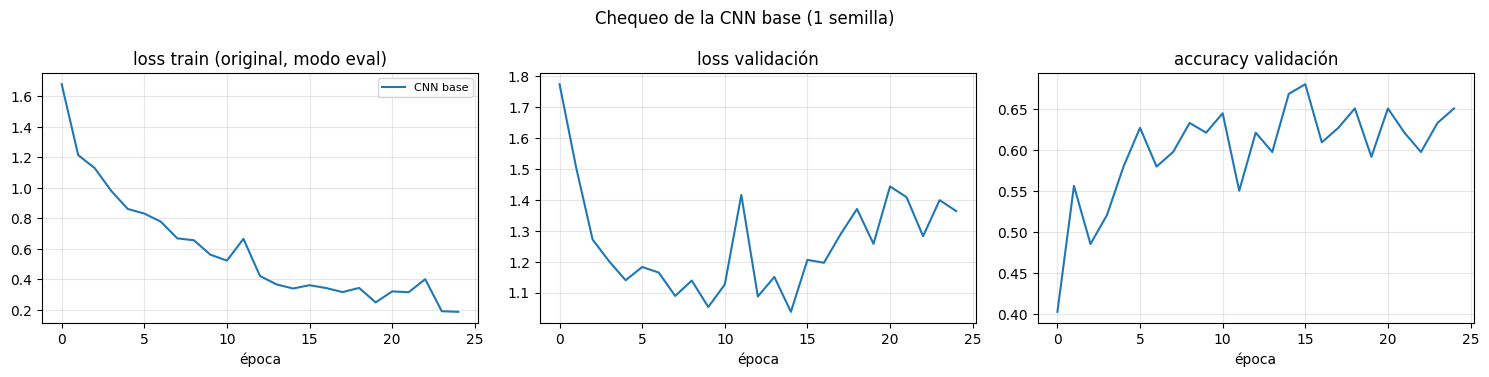

In [11]:
def plot_curves(hists, title):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for name, h in hists.items():
        ax[0].plot(h["train_loss"], label=name); ax[1].plot(h["val_loss"], label=name); ax[2].plot(h["val_acc"], label=name)
    for a, t in zip(ax, ["loss train (original, modo eval)", "loss validación", "accuracy validación"]): a.set_title(t); a.set_xlabel("época"); a.grid(alpha=.3)
    ax[0].legend(fontsize=8); fig.suptitle(title); plt.tight_layout(); plt.show()
t0 = time.time(); _, h = fit(BASE, 0)
print(f"mejor época {h['best_epoch']} | val_acc {h['val_acc'][h['best_epoch']-1]:.3f} | train_acc {h['train_acc'][h['best_epoch']-1]:.3f} | {np.mean(h['epoch_time']):.2f} s/época | total {time.time()-t0:.0f}s")
plot_curves({"CNN base": h}, "Chequeo de la CNN base (1 semilla)")

## 5. De la MLP a la CNN
Misma resolución, mismo split, mismo criterio de parada, 3 semillas. Además de val_acc se mide:
- **Parámetros y tiempo por época.**
- **Robustez a traslaciones**: se evalúa el modelo ya entrenado sobre validación con imágenes **trasladadas** al azar hasta ±`SHIFT` px (la convolución es equivariante a traslaciones y con pooling aproximadamente invariante; la MLP no tiene esa propiedad).

,modelo,params,val_acc,std,train_acc,brecha,mejor_epoca,t_epoca_s,val_acc_trasladada,caida_por_traslacion
0,MLP 32px,1640201,0.4951,0.0388,0.7378,0.2427,5.0000,0.0334,0.4346,0.0605
1,MLP 64px,6358793,0.5247,0.0433,0.7042,0.1796,6.6667,0.0567,0.4372,0.0874
2,CNN 32px,156057,0.6568,0.0048,0.8564,0.1996,10.6667,0.0786,0.5891,0.0677
3,CNN 64px,549273,0.6154,0.0145,0.7628,0.1475,10.0000,0.0734,0.5385,0.0769


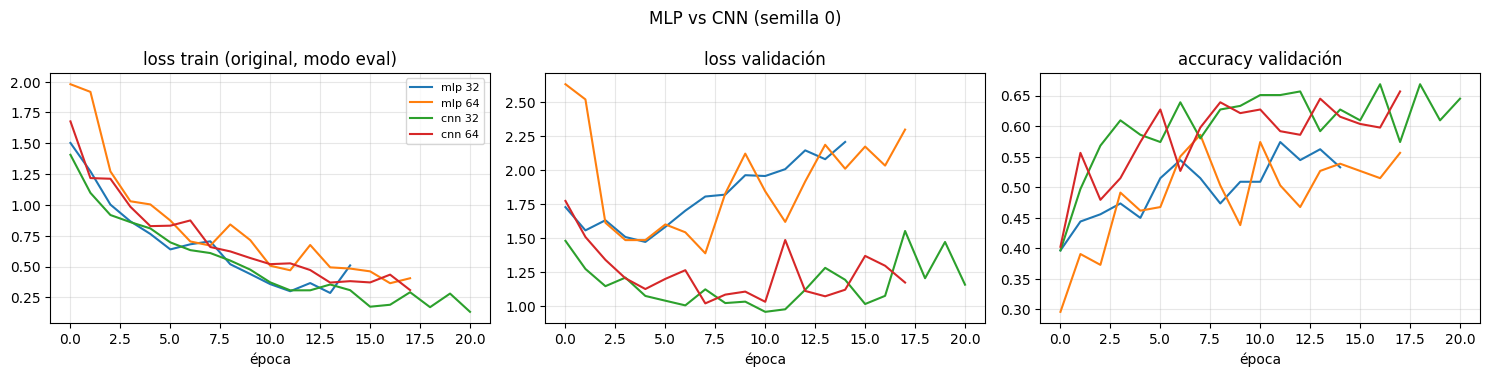

Referencia: azar = 0.111 | error estándar binomial de un accuracy ~0.5 con 169 imágenes de val = 0.038


In [12]:
SHIFT = {32: 4, 64: 8}
rows, store = [], {}
for model_name, size in [("mlp", 32), ("mlp", 64), ("cnn", 32), ("cnn", 64)]:
    cfg = {**BASE, "model": model_name, "size": size}
    r, ms, hs = run(cfg)
    clean = [evaluate(m, idx_va, size)[1] for m in ms]; shifted = [np.mean([evaluate(m, idx_va, size, shift=SHIFT[size])[1] for _ in range(3)]) for m in ms]
    rows.append(dict(modelo=f"{model_name.upper()} {size}px", params=r["params"], val_acc=r["val_acc"], std=r["val_acc_std"], train_acc=r["train_acc"],
                     brecha=r["brecha"], mejor_epoca=r["best_epoch"], t_epoca_s=r["t_epoca_s"],
                     val_acc_trasladada=np.mean(shifted), caida_por_traslacion=np.mean(clean) - np.mean(shifted)))
    store[f"{model_name} {size}"] = hs[0]
display(pd.DataFrame(rows).round(4))
plot_curves(store, "MLP vs CNN (semilla 0)")
print(f"Referencia: azar = {1/NUM_CLASSES:.3f} | error estándar binomial de un accuracy ~0.5 con {len(idx_va)} imágenes de val = {np.sqrt(.25/len(idx_va)):.3f}")

### ✏️ TU ANÁLISIS 1 - De la MLP a la CNN
1. Compará MLP y CNN en **parámetros, val_acc (± desvío), brecha train-val, tiempo por época y época de convergencia**. ¿La diferencia de val_acc supera el ruido entre semillas y el error estándar de la validación?
2. ¿Por qué la MLP necesita tantos más parámetros? Calculá a mano cuántos parámetros tiene la primera capa de la MLP a 32 y a 64 px y explicá qué pasaría a 224 px. ¿Qué propiedades de la convolución (pesos compartidos, conectividad local) cambian ese número?
3. Mirá la **caída por traslación**: ¿cuál de los dos modelos se degrada menos y por qué? ¿Es coherente con la teoría de equivarianza/invarianza, o el ruido no permite concluir?
4. ¿Qué rol cumple la normalización de entrada acá (mencionen cómo se calculó) y qué esperarían si no se hiciera?

---

**1.** La CNN es mejor y usa muchos menos parámetros. A 64 px obtiene 0,615 ± 0,015 contra 0,525 ± 0,043 de la MLP, con 11,6 veces menos parámetros (549.273 contra 6.358.793). A 32 px obtiene 0,657 ± 0,005 contra 0,495 ± 0,039. Las dos diferencias superan el desvío entre semillas y el error estándar de la validación (0,038). La MLP llega a su mejor época antes (5 a 7) y después su `val_loss` sube de alrededor de 1,5 a más de 2,0, un sobreajuste más fuerte. La CNN es más lenta por época (≈0,075 s contra 0,03 a 0,06 s en GPU), porque cada peso de una convolución se aplica en todas las posiciones de la imagen.

**2.** La primera capa de la MLP conecta cada valor de la imagen con 512 neuronas: 3.072 × 512 + 512 = 1.573.376 parámetros a 32 px, 6.291.968 a 64 px, y serían 77.070.848 a 224 px. Crece con el cuadrado del lado. La convolución evita esto con pesos compartidos (el mismo filtro recorre toda la imagen) y conectividad local (cada salida mira solo 3×3 píxeles). En la CNN, lo único que crece con la resolución es la `Linear` de la cabeza.

**3.** Al trasladar las imágenes de validación, las caídas son parecidas: 0,061 la MLP y 0,068 la CNN a 32 px, y 0,087 y 0,077 a 64 px. La diferencia está muy por debajo del error estándar, así que no se puede concluir que la CNN sea más robusta. Tiene sentido: las convoluciones y el pooling toleran traslaciones, pero la `Linear` final tiene un peso por posición y no lo hace. Aun trasladada, la CNN sigue siendo mejor (0,539 contra 0,437 a 64 px).

**4.** La media y el desvío por canal se calcularon solo con train, después del split (a 64 px: media [0,743; 0,572; 0,565] y desvío [0,162; 0,164; 0,186]). Así las entradas quedan centradas en cero y con escala parecida en los tres canales, lo que facilita la optimización. Usar solo train evita que el preprocesamiento tenga información de validación o test. Sin normalizar, esperaría un entrenamiento más lento o inestable, aunque no lo probé.

## 6. Decisiones de arquitectura convolucional
Se parte de la CNN base y se cambia **un factor a la vez** (3 semillas cada uno): profundidad, tamaño del kernel, cantidad de filtros y resolución de entrada. Se reporta además el **campo receptivo** teórico y los parámetros (que incluyen la capa `Linear` de la cabeza, cuyo tamaño depende de la resolución y la profundidad).

,variante,campo_receptivo,params,val_acc,val_acc_std,train_acc,brecha,best_epoch,t_epoca_s,t_total_s
0,"base (3 bloques, k=3, 16 filtros, 64px)",18,549273,0.6075,0.0228,0.7806,0.1731,10.6667,0.0783,1.6305
1,2 bloques,8,1055001,0.5838,0.0148,0.7141,0.1303,8.0000,0.0664,1.1958
2,4 bloques,38,361113,0.6686,0.0338,0.8682,0.1996,19.0000,0.0894,2.6135
3,kernel 5,32,591001,0.6292,0.0155,0.8465,0.2173,19.0000,0.0846,2.4392
4,kernel 7,46,653593,0.5779,0.0195,0.7200,0.1421,15.0000,0.1114,2.7821
5,8 filtros,18,269521,0.6805,0.0377,0.8966,0.2161,12.3333,0.0756,1.6837
6,32 filtros,18,1143337,0.6114,0.0459,0.8090,0.1975,15.3333,0.1142,2.8933
7,32 px,18,156057,0.6430,0.0148,0.8011,0.1581,7.6667,0.0624,1.1057
8,96 px,18,1204633,0.5602,0.0449,0.7424,0.1823,12.0000,0.1234,2.7124


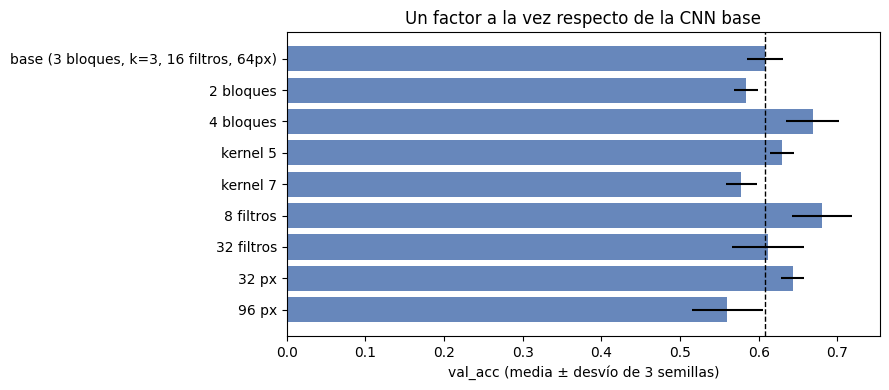

In [13]:
ARCH_VARIANTS = {
    "base (3 bloques, k=3, 16 filtros, 64px)": {},
    "2 bloques": dict(n_blocks=2), "4 bloques": dict(n_blocks=4),
    "kernel 5": dict(kernel=5), "kernel 7": dict(kernel=7),
    "8 filtros": dict(filters=8), "32 filtros": dict(filters=32),
    "32 px": dict(size=32), "96 px": dict(size=96),
}
rows, arch_cfgs, arch_hist = [], {}, {}
for name, delta in ARCH_VARIANTS.items():
    cfg = {**BASE, **delta}; r, ms, hs = run(cfg)
    rows.append(dict(variante=name, campo_receptivo=rf_full(cfg["n_blocks"], cfg["kernel"]), **r)); arch_cfgs[name] = cfg; arch_hist[name] = hs[0]
tab_arch = pd.DataFrame(rows)
display(tab_arch[["variante", "campo_receptivo", "params", "val_acc", "val_acc_std", "train_acc", "brecha", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tab_arch["variante"], tab_arch["val_acc"], xerr=tab_arch["val_acc_std"], color="#4c72b0", alpha=.85); ax.invert_yaxis()
ax.axvline(tab_arch["val_acc"].iloc[0], color="k", ls="--", lw=1); ax.set_xlabel("val_acc (media ± desvío de 3 semillas)"); ax.set_title("Un factor a la vez respecto de la CNN base"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 2 - Arquitectura convolucional
1. ¿Qué factores cambian la val_acc **más allá del ruido entre semillas** (desvío de la tabla) y cuáles no? Sean explícitos sobre qué diferencias son pequeñas respecto del ruido.
2. **Profundidad y kernel:** relacionen el campo receptivo con el tamaño de la imagen y con lo que se quiere detectar en una lesión (bordes, texturas, asimetría global). ¿Qué esperaban de agregar bloques o agrandar el kernel y qué se observó? Comparen costo (parámetros y tiempo) vs. ganancia.
3. **Resolución de entrada (32/64/96):** ¿cómo cambia la cantidad de parámetros de la capa `Linear` de la cabeza y por qué? ¿Qué se gana (detalle disponible) y qué se pierde (cómputo, campo receptivo relativo a la imagen)? Con tan pocas imágenes por clase, ¿qué límite tiene este experimento?
4. ¿Qué no se puede concluir con un diseño de "un factor a la vez" y 3 semillas?

---

**1.** Frente a la base (0,608 ± 0,023), solo dos variantes superan el desvío y el error estándar (≈0,037), y por poco: **8 filtros** (0,681 ± 0,038) y **4 bloques** (0,669 ± 0,034). Ninguna llega al doble del error estándar, así que las tomo como indicios. Las demás (kernel 5, kernel 7, 32 filtros, 2 bloques, 32 px) quedan a menos de 0,04 de la base: dentro del ruido. 96 px (0,560 ± 0,045) está en el límite.

**2.** Más bloques agrandan el campo receptivo: 8 px con 2 bloques, 18 con 3 y 38 con 4 (59% de la imagen). Eso ayuda a ver la forma global de la lesión, además de bordes y texturas. Coincide con lo observado: 4 bloques fue la mejor variante de profundidad y 2 bloques la peor (0,584). Además, 4 bloques usa menos parámetros (361.113), porque la `Linear` recibe un mapa más chico, y cuesta casi el mismo tiempo. Kernel 7 llega a un campo receptivo de 46 px y aun así rindió peor (0,578), con más parámetros y más tiempo. El campo receptivo solo no alcanza; mi hipótesis es que apilar bloques permite combinar patrones simples en complejos, mientras que filtros de 7×7 tienen muchos pesos para tan pocas imágenes. 8 filtros rinde igual o mejor con la mitad de parámetros, lo que sugiere que con ≈60 imágenes por clase alcanza una red chica.

**3.** La `Linear` recibe 64 × (size/8)² entradas: 131.200 parámetros a 32 px, 524.416 a 64 y 1.179.776 a 96, porque crece con el cuadrado del lado. Más resolución da más detalle, pero cuesta el doble de tiempo (0,123 s contra 0,062 s por época) y achica el campo receptivo relativo: 56% de la imagen a 32 px y 19% a 96. Acá la resolución baja rindió igual o mejor (32 px: 0,643; 96 px: 0,560), como en la sección 5. El límite es que, con ≈60 imágenes por clase, más resolución significa muchos más parámetros para los mismos datos, y con la arquitectura fija no se puede separar el efecto del detalle del efecto del campo receptivo.

**4.** No se pueden ver interacciones (por ejemplo, 4 bloques junto con 8 filtros), no se pueden separar del ruido diferencias de 3 a 5 puntos, y con un solo split no sabemos si se repetirían. Además, al quedarse con la mejor de 9 variantes, el ganador tiende a estar inflado: la configuración final dio 0,639 en validación, menos que el 0,681 de "8 filtros".

## 7. Data augmentation
Con ~60 imágenes por clase en train, el overfitting es esperable. Se comparan cuatro niveles de augmentation (los de la sección 3) con la CNN base y 3 semillas. En cada caso, **train queda con las imágenes originales más `AUG_COPIES` copias aumentadas de cada una**; val y test no se tocan.

,augmentation,n_train,val_acc,val_acc_std,train_acc,brecha,val_loss,best_epoch,t_epoca_s,t_total_s
0,ninguna,506,0.6114,0.0363,0.7846,0.1731,1.0170,11.3333,0.0803,1.7001
1,flips,1518,0.5937,0.0369,0.7404,0.1468,1.0469,5.6667,0.2267,3.5353
2,flips+rot90,1518,0.6548,0.0112,0.8808,0.2259,1.0697,15.0000,0.2236,5.5980
3,flips+rot90+color,1518,0.6154,0.0167,0.7767,0.1613,1.0208,8.6667,0.2204,4.1363


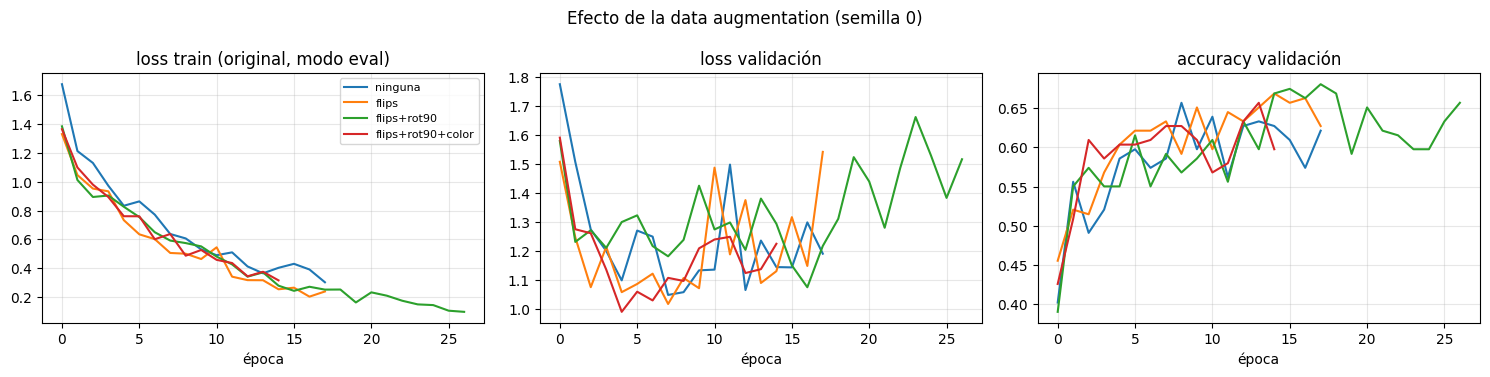

In [14]:
rows, aug_hist = [], {}
for name in AUGS:
    cfg = {**BASE, "aug": name}; r, ms, hs = run(cfg)
    rows.append(dict(augmentation=name, n_train=len(train_set(64, name)[0]), **r)); aug_hist[name] = hs[0]
tab_aug = pd.DataFrame(rows)
display(tab_aug[["augmentation", "n_train", "val_acc", "val_acc_std", "train_acc", "brecha", "val_loss", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
plot_curves(aug_hist, "Efecto de la data augmentation (semilla 0)")

### ✏️ TU ANÁLISIS 3 - Overfitting y augmentation
1. Demostrá el overfitting de la CNN sin augmentation **con números**: brecha train-val, época donde la `val_loss` empieza a subir.
2. ¿Qué cambia con cada nivel de augmentation sobre la **brecha**, la `val_loss`, la `val_acc`, la **época de convergencia** y el **tiempo total**? ¿Por qué cada época cuesta más con augmentation? ¿Cuál de las mejoras supera el ruido entre semillas?
3. Discutan desde el dominio (dermatología) qué transformaciones tienen sentido y cuáles podrían **destruir información** (por ejemplo, el color o la escala). ¿Qué otras augmentations probarían?
4. ¿Por qué es importante que la augmentation se haga **después** del split y **solo en train**? ¿Qué pasaría con las métricas si se aumentara antes de dividir?
5. Compará con lo que vieron en el TP3: ¿qué diferencia hay entre regularizar con dropout/L2 (restricciones sobre los pesos) y con augmentation (más datos sintéticos)?

---

**1.** Sin augmentation, la mejor época tiene 0,785 en train y 0,611 en validación: una brecha de 0,173. En el chequeo de la sección 4.2, la `val_loss` llega a su mínimo (≈1,04) en la época 15 y después sube hasta ≈1,45 en la época 21, mientras la loss de train sigue bajando hasta 0,19. El modelo mejora en train y empeora en validación: es varianza alta.

**2.** Los resultados fueron 0,611 ± 0,036 sin augmentation, 0,594 ± 0,037 con flips, 0,655 ± 0,011 con flips y rotaciones, y 0,615 ± 0,017 agregando color. Ninguna mejora supera claramente el ruido. La mejor (flips y rotaciones, +0,044) tiene además la brecha más grande (0,226 contra 0,173) y no baja la `val_loss` (1,070 contra 1,017), así que no hay evidencia clara de que haya reducido el overfitting. Mi hipótesis es que las copias se generan una sola vez, y el modelo también puede memorizarlas. Cada época cuesta ≈2,8 veces más (0,22 contra 0,08 s), porque train pasa de 506 a 1.518 imágenes, y el tiempo total sube de 1,7 s a entre 3,5 y 5,6 s.

**3.** Los flips y las rotaciones tienen sentido, porque una lesión vista con dermatoscopio no tiene orientación. El color, en cambio, es parte del diagnóstico (el rojo de las lesiones vasculares, los marrones y azulados de las pigmentadas). Cambiar el tono podría convertir una lesión en otra; acá solo se cambian brillo y contraste por igual en los tres canales. La escala también es delicada, porque el tamaño de la lesión importa. Probaría rotaciones de cualquier ángulo, recortes chicos y, sobre todo, transformaciones nuevas en cada época.

**4.** Si se aumentara antes del split, copias de una misma imagen podrían quedar en train y en validación o test, como con los duplicados del EDA, y las métricas saldrían infladas. Validación y test no se aumentan porque tienen que representar imágenes reales.

**5.** Dropout y L2 restringen el modelo, mientras que la augmentation agrega datos que expresan algo que sabemos que es cierto (la orientación no importa). En mis TPs ninguna de las dos ayudó mucho: en el TP3, L2 no mejoró la validación y dropout la mejoró menos de un punto, y acá la augmentation no superó el ruido.

## 8. Elección del modelo final y evaluación en TEST (una sola vez)
Se arma la configuración final tomando, entre las variantes de arquitectura, la de **mejor val_acc media** y, entre las de augmentation, la de **mejor val_acc media** (ambas ya medidas arriba). Se puede forzar otra decisión con `FINAL_OVERRIDE` (justificándola en el análisis). Es una decisión *greedy* de un factor a la vez: no se garantiza que la combinación sea mejor que cada parte.

Luego se entrenan la config final y la MLP de referencia (64 px) con las semillas `SEEDS_FINAL` y se evalúan en test **una única vez**. No se vuelve a tocar nada después de ver estos números.

In [15]:
best_arch = tab_arch.sort_values(["val_acc", "params"], ascending=[False, True]).iloc[0]["variante"]
best_aug  = tab_aug.sort_values("val_acc", ascending=False).iloc[0]["augmentation"]
FINAL_CFG = {**arch_cfgs[best_arch], "aug": best_aug}
FINAL_OVERRIDE = None          # por ejemplo: dict(n_blocks=4, aug="flips+rot90")
if FINAL_OVERRIDE: FINAL_CFG = {**FINAL_CFG, **FINAL_OVERRIDE}
print("Mejor arquitectura (val):", best_arch, "| mejor augmentation (val):", best_aug)
print("Config final:", FINAL_CFG)
rf_, ms_, hs_ = run(FINAL_CFG)
print(f"Config final en validación: val_acc {rf_['val_acc']:.3f} ± {rf_['val_acc_std']:.3f} | brecha {rf_['brecha']:.3f} | mejor época {rf_['best_epoch']:.1f} | {rf_['t_total_s']:.0f}s por entrenamiento")

Mejor arquitectura (val): 8 filtros | mejor augmentation (val): flips+rot90
Config final: {'model': 'cnn', 'size': 64, 'n_blocks': 3, 'filters': 8, 'kernel': 3, 'dropout': 0.2, 'lr': 0.003, 'aug': 'flips+rot90'}
Config final en validación: val_acc 0.639 ± 0.017 | brecha 0.170 | mejor época 7.7 | 4s por entrenamiento


,modelo,params,test_acc,test_acc_std,test_f1_macro,f1_std,tiempo_entrenamiento_s
0,CNN final,269521,0.6805,0.0353,0.6671,0.0363,4.0013
1,MLP 64px,6358793,0.5041,0.0534,0.4872,0.0572,0.9855


Error estándar binomial del test (169 imágenes): ±0.036 | azar: 0.111
                            precision    recall  f1-score   support

         Actinic keratosis       0.64      0.35      0.45        20
         Atopic Dermatitis       0.75      0.94      0.83        16
          Benign keratosis       0.95      0.90      0.92        20
            Dermatofibroma       0.56      0.50      0.53        20
         Melanocytic nevus       0.65      0.85      0.74        20
                  Melanoma       0.62      0.40      0.48        20
   Squamous cell carcinoma       0.38      0.60      0.46        20
Tinea Ringworm Candidiasis       0.71      0.38      0.50        13
           Vascular lesion       0.87      1.00      0.93        20

                  accuracy                           0.66       169
                 macro avg       0.68      0.66      0.65       169
              weighted avg       0.68      0.66      0.65       169



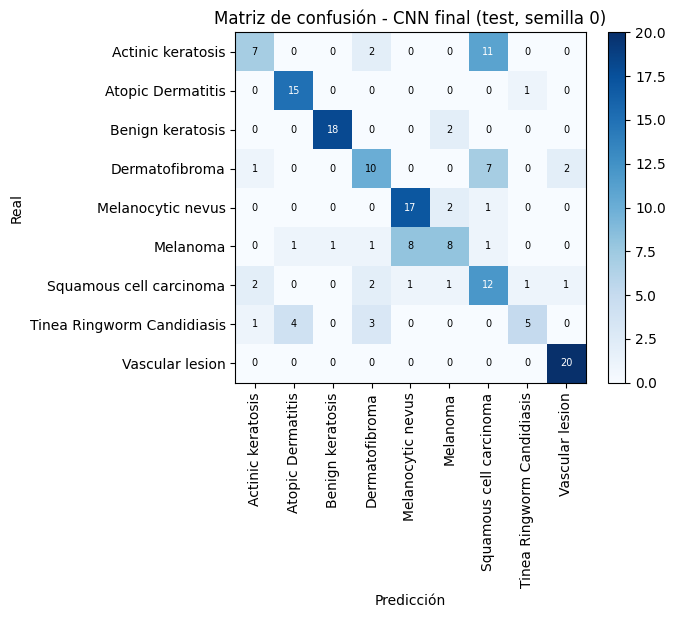

In [16]:
# ---- EVALUACIÓN EN TEST: se ejecuta una sola vez ----
final_rows, final_models, final_preds = [], {}, {}
for name, cfg in [("CNN final", FINAL_CFG), ("MLP 64px", {**BASE, "model": "mlp", "size": 64})]:
    accs, f1s, times = [], [], []
    for s in SEEDS_FINAL:
        m, h = fit(cfg, s); _, a, p = evaluate(m, idx_te, cfg["size"])
        accs.append(a); f1s.append(f1_score(labels[idx_te], p, average="macro")); times.append(sum(h["epoch_time"]))
        if s == SEEDS_FINAL[0]: final_models[name], final_preds[name] = m, p
    final_rows.append(dict(modelo=name, params=h["n_params"], test_acc=np.mean(accs), test_acc_std=np.std(accs), test_f1_macro=np.mean(f1s), f1_std=np.std(f1s), tiempo_entrenamiento_s=np.mean(times)))
final = pd.DataFrame(final_rows); display(final.round(4))
se = np.sqrt(final.loc[0, "test_acc"] * (1 - final.loc[0, "test_acc"]) / len(idx_te))
print(f"Error estándar binomial del test ({len(idx_te)} imágenes): ±{se:.3f} | azar: {1/NUM_CLASSES:.3f}")
p = final_preds["CNN final"]
print(classification_report(labels[idx_te], p, target_names=class_names, zero_division=0))
cm = confusion_matrix(labels[idx_te], p)
plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90); plt.yticks(range(NUM_CLASSES), class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES): plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title(f"Matriz de confusión - CNN final (test, semilla {SEEDS_FINAL[0]})"); plt.tight_layout(); plt.show()

## 9. ¿Qué aprende la red?
Se muestran (sobre imágenes de **validación**, no de test): los filtros de la primera convolución, los **mapas de activación** de la primera y la última capa convolucional para una imagen, y una galería de imágenes **mal clasificadas**.

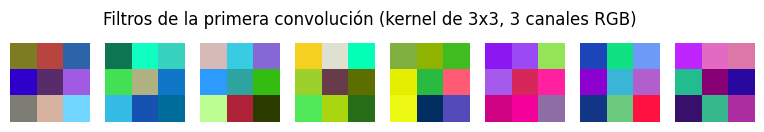

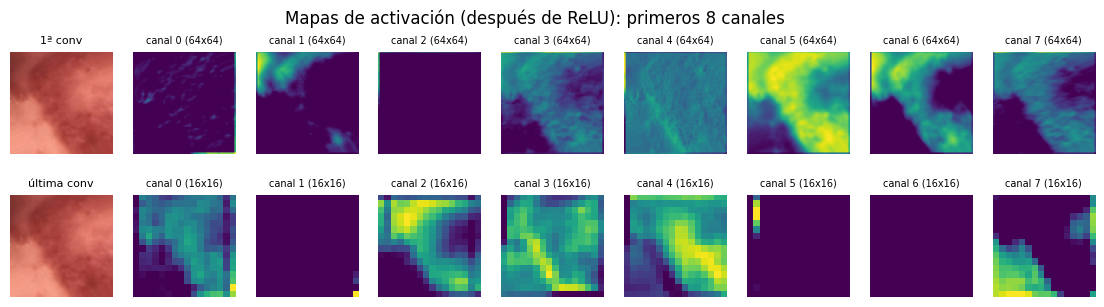

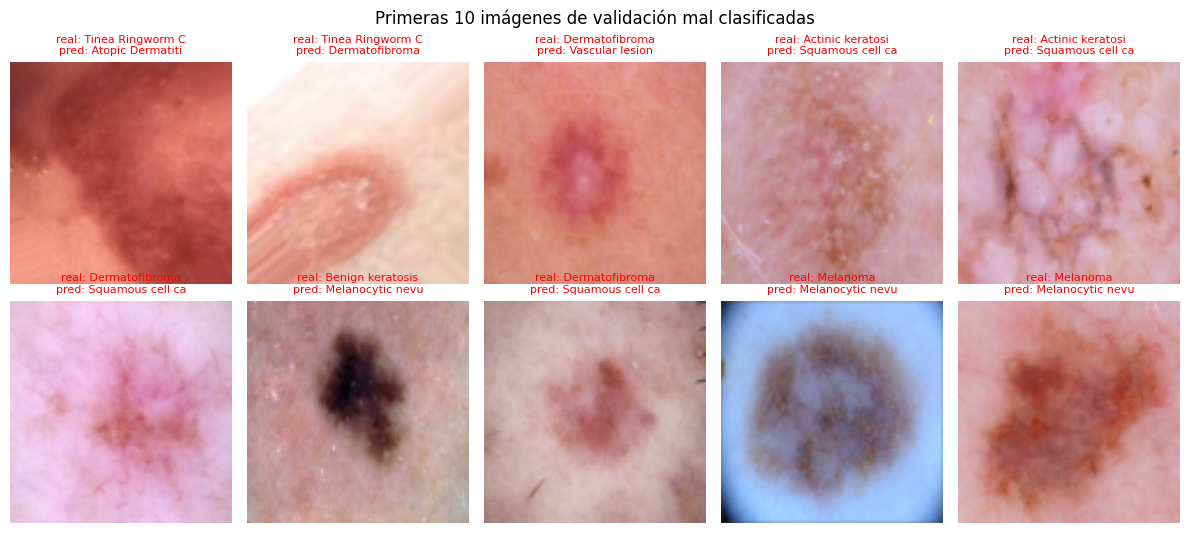

In [17]:
model = final_models["CNN final"].eval(); size = FINAL_CFG["size"]
W = model.features[0].weight.detach().cpu(); n = min(W.shape[0], 16)
fig, ax = plt.subplots(1, n, figsize=(1.2 * n, 1.5))
for i in range(n):
    w = W[i]; w = (w - w.min()) / (w.max() - w.min() + 1e-8); ax[i].imshow(w.permute(1, 2, 0), interpolation="nearest"); ax[i].axis("off")
fig.suptitle("Filtros de la primera convolución (kernel de %dx%d, 3 canales RGB)" % (W.shape[2], W.shape[3])); plt.show()

relu_pos = [i for i, l in enumerate(model.features) if isinstance(l, nn.ReLU)]
xi, yi = get_eval_batch(size, idx_va[:1])
with torch.no_grad(): a_first = model.features[:relu_pos[0] + 1](xi)[0].cpu(); a_last = model.features[:relu_pos[-1] + 1](xi)[0].cpu()
fig, ax = plt.subplots(2, 9, figsize=(14, 3.4))
for r_, (a, nm) in enumerate([(a_first, "1ª conv"), (a_last, "última conv")]):
    ax[r_, 0].imshow(X_U8[size][idx_va[0]].permute(1, 2, 0)); ax[r_, 0].set_title(nm, fontsize=8); ax[r_, 0].axis("off")
    for k in range(8): ax[r_, k + 1].imshow(a[k], cmap="viridis"); ax[r_, k + 1].axis("off"); ax[r_, k + 1].set_title(f"canal {k} ({a.shape[1]}x{a.shape[2]})", fontsize=7)
plt.suptitle("Mapas de activación (después de ReLU): primeros 8 canales"); plt.show()

_, _, pv = evaluate(model, idx_va, size)
bad = [i for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]; pbad = [p_ for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]
fig, ax = plt.subplots(2, 5, figsize=(12, 5.4))
for a, i, pr in zip(ax.flat, bad, pbad):
    a.imshow(X_U8[96][i].permute(1, 2, 0)); a.axis("off"); a.set_title(f"real: {class_names[labels[i]][:16]}\npred: {class_names[pr][:16]}", fontsize=8, color="red")
plt.suptitle("Primeras 10 imágenes de validación mal clasificadas"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 4 - Resultados finales e interpretación
1. **Consistencia val vs. test:** ¿el resultado de test es coherente con la validación? Tengan en cuenta el error estándar binomial del test y que elegimos el mejor entre varias configuraciones sobre validación (sesgo optimista).
2. **CNN vs. MLP en test:** ¿la diferencia supera el ruido entre semillas (± desvío) y el error estándar del test? ¿Se justifica el costo en parámetros/tiempo?
3. **Matriz de confusión y reporte por clase:** ¿qué clases se confunden más y por qué (similitud clínica/visual)? En este problema, ¿es igual de grave confundir cualquier par de clases? ¿Qué métrica (recall de melanoma, F1 macro, otra) les parece más relevante que el accuracy y por qué?
4. **Filtros, mapas de activación y errores:** ¿qué detectan las primeras capas y qué cambia en la última (tamaño espacial, nivel de abstracción)? ¿Qué patrones comunes tienen las imágenes mal clasificadas?
5. **Sesgos y limitaciones:** retomen el EDA (resoluciones y color por clase, duplicados). ¿Qué sesgos del dataset podrían inflar o distorsionar los números? Tamaño del dataset, una sola partición, pocas semillas, validación chica: ¿qué harían con más tiempo?

---

**1.** La configuración final (8 filtros, flips y rotaciones) se eligió solo con validación, y el test se usó una única vez. La combinación dio 0,639 ± 0,017 en validación, menos que cada parte por separado, lo que muestra que elegir de a un factor no garantiza una buena combinación. En test dio 0,681 ± 0,035 de accuracy y 0,667 de F1 macro. La diferencia con validación (+0,04) es del orden del error estándar del test (±0,036), así que son coherentes. Esperaba que validación fuera optimista, pero con 169 imágenes esa diferencia es ruido.

**2.** En test, la CNN obtiene 0,681 ± 0,035 contra 0,504 ± 0,053 de la MLP: una diferencia de 0,18, unas cinco veces el error estándar, y real. La CNN usa 23,6 veces menos parámetros (269.521 contra 6.358.793). Tarda más en entrenar (4,0 s contra 1,0 s), por la augmentation y por el costo de la convolución, pero con tiempos de segundos el costo se justifica.

**3.** Las peores clases son Actinic keratosis (recall 0,35; 11 de 20 predichas como Squamous cell carcinoma), Tinea (0,38), Melanoma (0,40; 8 de 20 como nevus) y Dermatofibroma (0,50). Las mejores son Vascular lesion (20 de 20), Benign keratosis (18 de 20) y Atopic Dermatitis (15 de 16). Las confusiones se dan entre lesiones parecidas: la queratosis actínica puede evolucionar a carcinoma escamoso y las dos se ven rosadas y difusas, y melanoma y nevus son las dos pigmentadas marrones. No todos los errores son igual de graves: decir "nevus" ante un melanoma puede retrasar el tratamiento de un cáncer. Por eso la métrica más relevante es el recall de las clases malignas (melanoma 0,40, carcinoma escamoso 0,60), junto con el F1 macro.

**4.** Los filtros de la primera convolución (3×3) se ven como manchas de color: detectan colores y contrastes locales. Sus mapas de 64×64 todavía se parecen a la imagen, y resaltan zonas claras u oscuras. Los de la última capa (16×16) son más gruesos y selectivos: varios canales casi apagados y otros que marcan el límite entre lesión y piel. Las imágenes mal clasificadas siguen el patrón de la matriz: lesiones rosadas difusas confundidas entre sí, lesiones marrones oscuras confundidas entre sí, y Tinea confundida con Atopic Dermatitis.

**5.** El sesgo principal es el del origen de las imágenes. Las clases con una fuente propia se reconocen mejor: Atopic Dermatitis, toda de 294×222, tiene recall 0,94, y Benign keratosis, mayormente de 1024×764, tiene 0,90. Las que comparten resolución se confunden entre sí: Actinic keratosis, Dermatofibroma y Squamous cell carcinoma, todas de 600×450, tienen 0,35, 0,50 y 0,60. Mi hipótesis es que el modelo usa en parte pistas de cómo se sacó la foto, y eso no funcionaría con otras fuentes. Además, el dataset es chico (error estándar de ±0,036), hay una sola partición, pocas semillas, resultados no exactamente repetibles en GPU, y una selección sobre validación que la vuelve algo optimista. Con más tiempo usaría validación cruzada, más semillas, augmentation nueva en cada época, combinaciones como 4 bloques con 8 filtros, y recortaría las imágenes para quitar las pistas de origen.

## Declaración de uso de IA

Sí, usé IA. Usé Claude (Anthropic) para ejecutar el notebook en Google Colab, para que me explicara el código convolucional y para redactar las respuestas de las celdas ✏️ a partir de los outputs de mi corrida. Yo revisé las respuestas y pedí cambios en la redacción. El código del TP es el del notebook original; solo agregué la celda que descarga el dataset.

## Versiones de las librerías
Versiones con las que se ejecutó este notebook (las de `requirements.txt`).

In [18]:
# Versiones usadas en esta corrida (para requirements.txt)
import platform
from importlib.metadata import version
print("Python", platform.python_version())
for p in ["torch", "numpy", "pandas", "matplotlib", "scikit-learn", "pillow"]:
    print(f"{p}=={version(p)}")

Python 3.13.16
torch==2.14.1+cu130
numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0
scikit-learn==1.6.1
pillow==11.3.0
